# Лабораторная работа №5. Сервис синтеза

**Курс «Синтез речи», Университет ИТМО**

Сборка компонентов работ №1-4 (нормализатор, предиктор пауз, G2P, FastSpeech 2) и нейросетевого вокодера HiFi-GAN в один конвейер «текст → звук», синтез тестовых фраз, оценка качества и скорости, сервис синтеза.

**Критерии приёмки (из README):**

| Критерий | Порог |
|---|---|
| Копи-синтез через HiFi-GAN звучит близко к оригиналу (аудио-конфигурация верна) | обязательно |
| Синтезированы 10 тестовых файлов разработанным трактом | обязательно |

**Артефакты:** `tts_pipeline.py` (конвейер), `frontend_rules.py` (правила подготовки свободного текста), `audio/` (10 + 5 фраз и три файла копи-синтеза), `report.ipynb` (этот отчёт); доп. задания - `service.py` (REST + Gradio), `finetune_vocoder.py` и `make_gta_mels.py` (дообучение вокодера), `lab5_eval.py` (все измерения отчёта).

**Кратко о результатах:**

- **Копи-синтез HiFi-GAN почти неотличим от записи** (оценка на слух: «если бы не знал, что это разные записи, не отличил бы»; слышен небольшой артефакт в самом начале). На 120 отложенных фразах: мел звука вокодера отличается от входного мела на 0,25 (L1, ln-единицы) против 1,22 у Гриффина-Лима, MCD 12,7 против 49,6 дБ, корреляция F0 с записью 0,97 против 0,89, CER Whisper 1,9 % (запись 1,7 %, Гриффин-Лим 2,1 %). Аудио-конфигурация моделей работы 4 совпадает с конфигурацией вокодера по всем параметрам.
- **Конвейер `TTSPipeline` синтезирует все 10 тестовых фраз и 5 фраз с разметкой** без правки текстов. Для этого понадобилось 14 изменений на стыках модулей (раздел 3.2), в том числе исправление падения нормализатора работы 1 на числах >= 1000 и нарезка длинного текста (модель работы 4 видела фразы не длиннее 10 с, позиционное кодирование coqui ограничено 58 с).
- **Качество:** простые фразы (eval_01, 02, 06, 08, 09) звучат нормально, CER всего набора 4,4 %. Слабые места - слова вне словаря (ацтекские имена eval_03 почти неразборчивы, начало eval_04 и «зальцбург» eval_07), смысловые омографы (eval_05: оба «передохнут» одинаковы; исправляется символом ударения `+`) и паузы/ударения в длинном тексте.
- **Скорость:** RTF 0,023 на GPU (RTX 3070 Ti) и 0,25 на CPU, т. е. в 40 и 4 раза быстрее реального времени; 70-77 % времени - вокодер. Время растёт линейно с длиной звука (~32 мс на секунду звука на GPU, ~250 мс на CPU).
- **Мелы работы 4 через HiFi-GAN** отвечают на открытый вопрос работы 4: на сглаженных мелах моделей без F0 нейровокодер «додумывает» гармоники, но на **постоянной высоте ~89 Гц** (разброс 1 полутон, корреляция с записью ~0) - монотонный «робоголос»; у `pitch_energy` - тон диктора (~118 Гц) и интонация (корреляция 0,58). Поэтому в конвейере `pitch_energy`.
- **Доп. 1 (управление паузами)** - сделано: теги разбираются до нормализатора и привязываются к токенам по сегментам (привязка по индексу слова из выданного `strip_markup` съезжает, раздел 8.1); `eval_p_4` = `eval_p_2`, `eval_p_5` = `eval_p_3` по фонемам и по звуку. **Доп. 3 (сервис)** - FastAPI + Gradio, проверен на всех тестовых фразах и «трудных» входах. **Доп. 2 (дообучение вокодера)** - сделано: дообучение на настоящих мелах (`gt`) и на GTA-мелах (`gta`), 12 000 шагов; копи-синтез точнее (MCD 12,7 -> 5,8), на мелах модели выигрыш в пределах шума (раздел 9).

In [1]:
import os, sys, json, re, time, warnings, logging, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display, Markdown

import lab5_eval as E                      # измерения (результаты кэшируются в runs/)
from tts_pipeline import TTSPipeline, Timings, strip_markup, split_markup, SIL
import TTS.tts.utils.visual                # noqa: F401 - coqui переключает matplotlib на Agg ...
%matplotlib inline

warnings.filterwarnings("ignore")
logging.getLogger("TTS").setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

AUDIO, RUNS = Path("audio"), Path("runs")
SR = 22050

def player(path, label=None, width=None):
    """Плеер с подписью."""
    if label:
        display(Markdown(f"**{label}** - `{path}`"))
    display(Audio(str(path), rate=SR))

D:\python_projects\ITMO\tts_labs_itmo\data\venv_tts\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Окружение

Используется окружение работы №4 (`data/venv_tts`: Python 3.13, torch 2.7.1+cu126, coqui-TTS из клона) с добавленными пакетами:

| пакет | зачем | замечание |
|---|---|---|
| `speechbrain 1.1.2` | вокодер HiFi-GAN | по README |
| `pymorphy3` (+ словари, `DAWG2-Python`) | признаки предиктора пауз (работа №2) и голоса морфологии в OOV-модели G2P (работа №3) | в `venv_tts` их не было: работы 1-3 жили в `.venv`. Версии взяты те же, что в `.venv`, - модели работ 2-3 сохранены pickle'ом и чувствительны к версиям (scikit-learn в обоих окружениях 1.9.1) |
| `fastapi`, `uvicorn`, `gradio` | сервис (доп. задание 3) | `gradio 6` требует `huggingface_hub>=1.16`, а `transformers 4.57` (Whisper, coqui) - `<1.0`; поставлен `gradio 5.50` с `huggingface_hub 0.36` (`pip check` чист) |

**Проблема Windows:** SpeechBrain по умолчанию раскладывает скачанную модель **символическими ссылками** из кэша HuggingFace, а Windows без прав администратора / режима разработчика их запрещает (`OSError: [WinError 1314] Клиент не обладает требуемыми правами`) - падает уже `check_vocoder.py`. Решение - `local_strategy=LocalStrategy.COPY` в `HIFIGAN.from_hparams` (поправлено в `check_vocoder.py` и в конвейере).

Проверка компонентов - одним объектом: `TTSPipeline` при создании загружает все пять (нормализатор, предиктор пауз, G2P, FastSpeech 2, HiFi-GAN), ниже - выход каждого на одной фразе.

In [2]:
import torch, TTS, speechbrain, sklearn, pymorphy3, fastapi, gradio, transformers
print(f"python {sys.version.split()[0]}, torch {torch.__version__}, cuda: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU {torch.cuda.get_device_name(0)}")
print(f"coqui-tts {TTS.__version__}, speechbrain {speechbrain.__version__}, scikit-learn {sklearn.__version__}, "
      f"pymorphy3 {pymorphy3.__version__}")
print(f"fastapi {fastapi.__version__}, gradio {gradio.__version__}, transformers {transformers.__version__}")

t0 = time.perf_counter()
P = TTSPipeline()           # модель по умолчанию - runs/pitch_energy работы 4 (раздел 3.3)
print(f"\nконвейер загружен за {time.perf_counter() - t0:.1f} с на {P.device}: {P.checkpoint.relative_to(Path('../..').resolve())}")

python 3.13.6, torch 2.7.1+cu126, cuda: True
GPU NVIDIA GeForce RTX 3070 Ti
coqui-tts 0.27.5, speechbrain 1.1.2, scikit-learn 1.9.1, pymorphy3 2.0.6
fastapi 0.163.2, gradio 5.50.0, transformers 4.57.6



конвейер загружен за 3.6 с на cuda: labs\lab4_acoustic\runs\pitch_energy\pitch_energy-November-11-2026_04+20AM-0569378\best_model_31650.pth


In [3]:
text = "В 1995-го году ТВ показало Шипе-Тотека, а он что?"
t = Timings()
norm = P.normalize(text)
tokens = P.tokenize(norm)
with_pauses = P.insert_pauses(tokens)
phones = P.to_phones(with_pauses)
print("1. нормализатор   :", norm)
print("2. токенизатор    :", tokens)
print("   предиктор пауз :", " ".join(with_pauses))
print("3. G2P            :", " ".join(phones))
mel = P.mel(phones)
print(f"4. FastSpeech 2   : мел {mel.shape}, диапазон [{mel.min():.2f}, {mel.max():.2f}]")
wav = P.vocode(mel)
print(f"5. HiFi-GAN       : {len(wav)} отсчётов = {mel.shape[1]} кадров x 256, {len(wav)/SR:.2f} с")
display(Audio(wav, rate=SR))

1. нормализатор   : В тысяча девятьсот девяносто пятого году тэ-вэ показало Шипе-Тотека, а он что?
2. токенизатор    : ['В', 'тысяча', 'девятьсот', 'девяносто', 'пятого', 'году', 'тэ-вэ', 'показало', 'Шипе-Тотека,', 'а', 'он', 'что?']
   предиктор пауз : В тысяча девятьсот девяносто пятого году тэ-вэ показало Шипе-Тотека, <SIL> а он что? <SIL>
3. G2P            : v t̪ ɨ sʲ ɪ tɕ ə dʲ ɪ vʲ ɪ tʲ s̪ o t̪ dʲ ɪ vʲ ɪ n̪ o s̪ t̪ ə pʲ a t̪ ə v ə ɡ ɐ d̪ u t̪ ɛ v ɛ p ə k ɐ z̪ a ɫ ə ʂ ɨ pʲ e t̪ ɐ tʲ e k ə <SIL> ɐ o n̪ ʂ t̪ o <SIL>


4. FastSpeech 2   : мел (80, 378), диапазон [-10.97, -0.06]
5. HiFi-GAN       : 96768 отсчётов = 378 кадров x 256, 4.39 с


## 2. Проверка вокодера

### 2.1. Аудио-конфигурация

`check_vocoder.py` сверяет аудио-конфигурацию с той, на которой обучен вокодер. В пяти параметрах она расходится с умолчаниями coqui - но **все модели работы №4 уже обучены на конфигурации вокодера** (её задавал скрипт обучения работы №4), так что для подключения HiFi-GAN ничего переобучать не нужно:

In [4]:
from TTS.config.shared_configs import BaseAudioConfig
default = BaseAudioConfig()
vocoder_cfg = dict(sample_rate=22050, fft_size=1024, win_length=1024, hop_length=256, num_mels=80, mel_fmin=0.0,
                   mel_fmax=8000.0, spec_gain=1.0, log_func="np.log", signal_norm=False, do_trim_silence=False)
lab4 = json.load(open(next(Path("../lab4_acoustic/runs/pitch_energy").rglob("config.json")), encoding="utf-8"))["audio"]
rows = [{"параметр": k, "умолчание coqui": getattr(default, k), "вокодер (LibriTTS 22k)": v, "модель работы 4": lab4[k],
         "совпадает": "да" if lab4[k] == v else "НЕТ"} for k, v in vocoder_cfg.items()]
pd.DataFrame(rows)

,параметр,умолчание coqui,вокодер (LibriTTS 22k),модель работы 4,совпадает
0,sample_rate,22050,22050,22050,да
1,fft_size,1024,1024,1024,да
2,win_length,1024,1024,1024,да
3,hop_length,256,256,256,да
4,num_mels,80,80,80,да
5,mel_fmin,0.0,0.0,0.0,да
6,mel_fmax,None,8000.0,8000.0,да
7,spec_gain,20,1.0,1.0,да
8,log_func,np.log10,np.log,np.log,да
9,signal_norm,True,False,False,да


### 2.2. Копи-синтез

Настоящая запись → мел тем же `AudioProcessor` → вокодер. Модели здесь нет, поэтому HiFi-GAN должен звучать почти как оригинал. Файлы `check_vocoder.py` (фраза `000000_RUSLAN`, из обучающей части - для вокодера это не важно, RUSLAN он не видел):

In [5]:
wav = sf.read("audio/natural.wav")[0]
from lab5_eval import audio_processor
ap = audio_processor()
mel = ap.melspectrogram(wav.astype(np.float32))
print(f"мел {mel.shape}, диапазон [{mel.min():.2f}, {mel.max():.2f}]  (README: натуральный мел RUSLAN ~ [-10.2, 0.5])")
for name, label in [("natural", "оригинал"), ("copysynth_hifigan", "копи-синтез HiFi-GAN"),
                    ("copysynth_griffinlim", "копи-синтез Гриффин-Лим (как в работе 4)")]:
    player(AUDIO / f"{name}.wav", label)

мел (80, 194), диапазон [-9.39, 1.35]  (README: натуральный мел RUSLAN ~ [-10.2, 0.5])


**оригинал** - `audio\natural.wav`

**копи-синтез HiFi-GAN** - `audio\copysynth_hifigan.wav`

**копи-синтез Гриффин-Лим (как в работе 4)** - `audio\copysynth_griffinlim.wav`

### 2.3. Сдвиг на 5 кадров: `inference_padding`

Первое сравнение копи-синтеза с оригиналом по кадрам дало для HiFi-GAN расстояние **хуже**, чем у Гриффина-Лима, а длину выхода - на 10 кадров больше входа. Причина - в `HifiganGenerator.inference` SpeechBrain: перед вокодированием мел дополняется `inference_padding = 5` повторёнными крайними кадрами **с каждой стороны**. Выход получается длиной `(T + 10) * 256` и сдвинут относительно мела на 1280 отсчётов (58 мс). На слух это незаметно (58 мс «растянутого» крайнего кадра в начале и в конце), но любое покадровое сравнение с входом ломается, а в конвейере к каждому куску добавляется по ~0,1 с. В конвейере и в измерениях запас обрезается (`trim_vocoder_padding`); файлы `audio/copysynth_*.wav` записаны выданным `check_vocoder.py` без обрезки.

In [6]:
from scipy.signal import correlate
from tts_pipeline import trim_vocoder_padding
x = sf.read(str(E.WAVS / "000020_RUSLAN.wav"))[0].astype(np.float32)
m = ap.melspectrogram(x)
raw = P.vocoder.decode_batch(torch.tensor(m).to(P.device)).squeeze().cpu().numpy()
for name, y in [("decode_batch как есть", raw), ("после обрезки", trim_vocoder_padding(P.vocoder, raw))]:
    lag = np.argmax(correlate(y, x, mode="full")) - (len(x) - 1)
    print(f"{name:22s}: {len(y)} отсчётов ({len(y)/256:.0f} кадров) при меле {m.shape[1]} кадров, сдвиг {lag:+d} отсчётов")
print("inference_padding =", P.vocoder.hparams.generator.inference_padding)

decode_batch как есть : 85248 отсчётов (333 кадров) при меле 323 кадров, сдвиг +1322 отсчётов
после обрезки         : 82688 отсчётов (323 кадров) при меле 323 кадров, сдвиг +42 отсчётов
inference_padding = 5


### 2.4. Насколько хорош копи-синтез: 120 отложенных фраз работы 4

`lab5_eval.copysynth()`: 120 оценочных фраз работы №4 (номер делится на 5, в обучении FastSpeech 2 не участвовали) через оба вокодера. Метрики:

- **L1 / MCD мела** - звук вокодера снова переводится в мел и сравнивается с мелом, который был подан на вход (покадрово, без DTW: время совпадает). Это доля входа, которую вокодер не смог воспроизвести;
- **F0** (pYIN, 50-300 Гц) - доля вокализованных кадров, средний тон, разброс, корреляция контура с записью, совпадение тон/не тон (V/UV);
- **CER / WER** распознавания Whisper large-v3-turbo (как в работе №4).

In [7]:
cs = E.copysynth()
nat_paths = {i: RUNS / "copysynth" / "natural" / f"{i}.wav" for i in cs.id.unique()}
f0_nat = E.f0_table(nat_paths, nat_paths)          # запись сама с собой: строка-эталон для F0
asr = E.asr()
cer = asr[asr.set == "copysynth"].groupby("variant")[["cer", "wer"]].mean()
cols = ["mel_l1", "mcd_frames", "ripple_out", "voiced", "f0_mean", "f0_std_st", "f0_corr", "f0_rmse_st", "vuv_acc"]
tab = cs.groupby("vocoder")[cols + ["seconds", "audio_s"]].mean()
tab.loc["natural", ["voiced", "f0_mean", "f0_std_st"]] = f0_nat[["voiced", "f0_mean", "f0_std_st"]].mean().values
tab["rtf"] = tab.seconds / tab.audio_s
tab = tab.join(cer).drop(columns=["seconds", "audio_s"]).loc[["natural", "hifigan", "griffinlim"]]
tab.round(3)

,mel_l1,mcd_frames,ripple_out,voiced,f0_mean,f0_std_st,f0_corr,f0_rmse_st,vuv_acc,rtf,cer,wer
vocoder,,,,,,,,,,,,
natural,0.000,0.000,1.044,0.379,123.754,3.135,NaN,NaN,NaN,NaN,0.017,0.051
hifigan,0.252,12.741,1.073,0.397,121.213,3.264,0.972,0.556,0.859,0.051,0.019,0.054
griffinlim,1.220,49.584,1.058,0.347,140.131,3.846,0.893,1.144,0.843,0.371,0.021,0.063


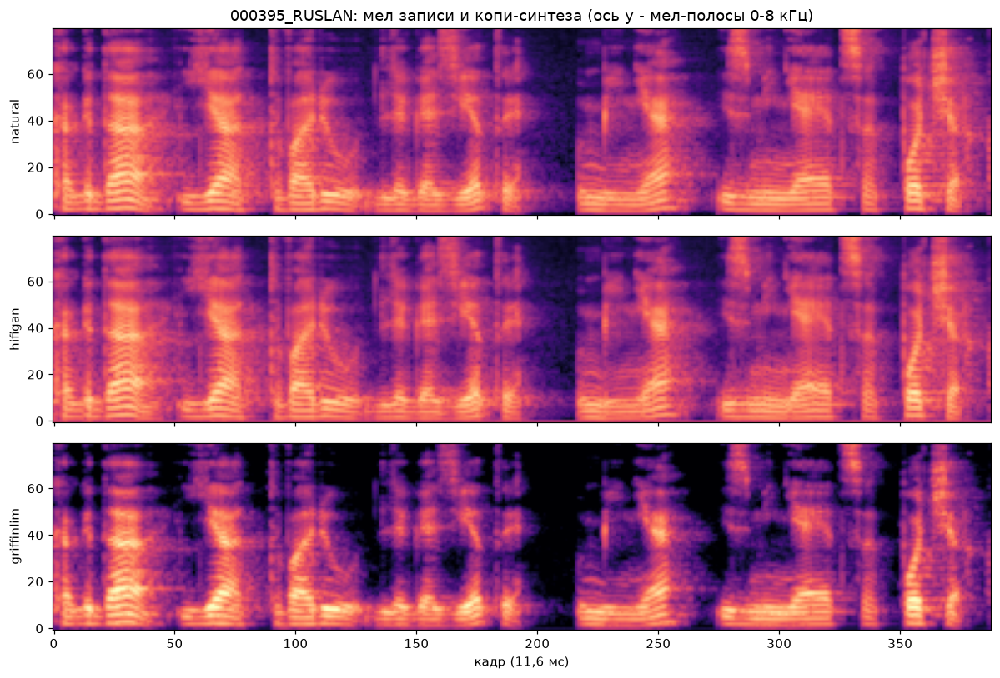

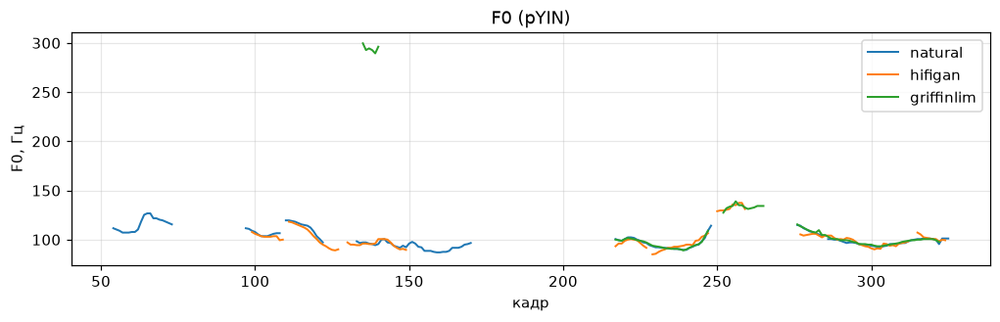

**hifigan** - `runs\copysynth\hifigan\000395_RUSLAN.wav`

**griffinlim** - `runs\copysynth\griffinlim\000395_RUSLAN.wav`

In [8]:
i = "000395_RUSLAN"
ys = {v: sf.read(str(RUNS / "copysynth" / v / f"{i}.wav"))[0].astype(np.float32) for v in ["natural", "hifigan", "griffinlim"]}
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, (v, y) in zip(axes, ys.items()):
    ax.imshow(ap.melspectrogram(y), origin="lower", aspect="auto", vmin=-11, vmax=1, cmap="magma")
    ax.set_ylabel(v); ax.grid(False)
axes[0].set_title(f"{i}: мел записи и копи-синтеза (ось y - мел-полосы 0-8 кГц)")
axes[-1].set_xlabel("кадр (11,6 мс)")
plt.tight_layout(); plt.show()

f0 = E.lab4_analysis.f0_contours({v: RUNS / "copysynth" / v / f"{i}.wav" for v in ys}, workers=3)
plt.figure(figsize=(11, 2.8))
for v, c in f0.items():
    plt.plot(np.where(c > 0, c, np.nan), label=v, lw=1.3)
plt.ylabel("F0, Гц"); plt.xlabel("кадр"); plt.legend(); plt.title("F0 (pYIN)"); plt.show()
for v in ["hifigan", "griffinlim"]:
    player(RUNS / "copysynth" / v / f"{i}.wav", v)

**Наблюдения:**

- **HiFi-GAN воспроизводит вход почти полностью.** Мел его звука отличается от поданного мела в среднем на 0,25 ln-единицы (у Гриффина-Лима - 1,22, впятеро больше), MCD 12,7 против 49,6 дБ. На спектрограммах у Гриффина-Лима размыты гармоники и «шумят» верхние полосы (несогласованная фаза), у HiFi-GAN спектр визуально совпадает с записью.
- **Тон.** Контур F0 HiFi-GAN почти совпадает с записью: корреляция 0,97, отклонение 0,56 полутона (у Гриффина-Лима 0,89 и 1,1 полутона; средний F0 140 Гц против 121 - pYIN на его звуке чаще ошибается на октаву вверх из-за фазового «дребезга»).
- **Разборчивость** копи-синтеза HiFi-GAN - CER 1,9 % при 1,7 % у записи; у Гриффина-Лима 2,1 %. ASR к качеству звучания почти нечувствителен: «телефонный» Гриффин-Лим распознаётся почти так же. Поэтому для вокодера главные метрики - мел и F0, а окончательная - слух.
- **На слух**: HiFi-GAN звучит почти как оригинал - «если бы не знал, что это разные записи, не отличил бы»; заметен небольшой артефакт в самом начале. Это начало - как раз то место, где генератор работает на дополненных краевых кадрах (`inference_padding`, раздел 2.3), а `check_vocoder.py` их не обрезает.
- Скорость: HiFi-GAN на GPU (~0,05 RTF вместе с первым вызовом) в ~7 раз быстрее Гриффина-Лима на CPU (32 итерации, ~0,37 RTF).

**Вывод:** аудио-конфигурация верна, вокодер пригоден; всё, что хуже копи-синтеза в итоговом звуке, - вклад акустической модели и фронтенда.

## 3. Конвейер синтеза

### 3.1. Схема

```
текст
  │  [markup]     доп. 1: <pause type=...> вырезаются ДО нормализатора; текст режется на сегменты
  ▼
normalize()       frontend_rules.prepare: символы -> пробел, `+` -> ударение, `--` -> тире,
  │               латиница -> кириллица, аббревиатуры по буквам
  │               + TextNormalizer.normalize(expand=True) работы 1 (числа, сокращения)
  ▼
tokenize()        tokenize_text работы 2: слово + пунктуация до следующего слова (label_raw)
  ▼
[предложения]     поток токенов режется на предложения (. ! ? … + заглавная/тире/кавычка)
  ▼ для каждого предложения
insert_pauses()   PausePredictor работы 2 (+ запросы тегов) -> <SIL>; <SIL> в конце предложения
  ▼
to_phones()       G2P работы 3 (словарь корпуса v3 -> словарь MFA -> OOV-модель -> контекст);
  │               <SIL> проходит насквозь; фонемы вне инвентаря отбрасываются с предупреждением
  ▼
[куски]           предложение длиннее 150 фонем режется по <SIL> на куски <= 150 фонем
  ▼ для каждого куска
mel()             FastSpeech 2 работы 4 (pitch_energy, 31 650 шагов)
  ▼
vocode()          HiFi-GAN (SpeechBrain, LibriTTS 22 кГц), обрезка inference_padding
  ▼
звук              куски склеиваются
```

Модели загружаются один раз в `TTSPipeline.__init__`; вызов `pipeline(text)` возвращает звук и `Timings` - время каждого этапа, RTF и журнал промежуточных форм (`timings.log`: нормализованный текст, токены, предложения с паузами, фонемы по кускам, предупреждения).

### 3.2. Что пришлось изменить, чтобы модули состыковались

| место | проблема (без исправления) | решение |
|---|---|---|
| работа 1, `ordinal_genitive` | **падение** `IndexError` на любом порядковом числе >= 1000: «в 1995-го году», «2000-го» - сервис падал бы на обычном тексте | тысячи читаются количественным («тысяча девятьсот девяносто пятого»); исправлено в `text_normalizer.py` |
| работа 1, числа с `-х` | «1800-х годах» -> «тысяча восемьсот годах» (окончание отрезалось) | `ordinal_plural_genitive`: «тысяча восьмисотых» |
| работа 1, удаление символов | `ТВ/спазм`, `икону+наши` -> `ТВспазм`, `иконунаши`: два слова склеиваются | `frontend_rules.symbols_to_spaces`: всё, что нормализатор удалил бы, сначала заменяется пробелом |
| работы 1 и 3, ударение `+` | G2P понимает `з+амок`, но нормализатор выбрасывает `+` | `+` перед гласной -> U+0301 (его нормализатор пропускает, G2P тоже понимает) |
| работы 1-2, `--` | типографское «тире» из двух дефисов не тире для нормализатора, признак `dash` предиктора пауз = 0 | ` -- ` -> ` — ` |
| работа 3, латиница | G2P оставляет только кириллицу: `fabric` получает **ноль фонем** и молча пропадает из звука | `transliterate_latin`: словарь англицизмов работы 1 + правила английского чтения |
| работа 3, аббревиатуры | `ТВ` читается как слово; в словаре MFA `тв` = `t̪ f` | слово капсом без гласных (или не из словаря) - по буквам: `тэ-вэ`; инициал `К.` перед строчной -> `ка` без точки |
| работы 2 и 4, конец фразы | предиктор пауз не решает за последнее слово, а **каждая** обучающая фраза работы 4 кончается `<SIL>` | `<SIL>` в конце каждого предложения |
| работа 2, теги пауз | выданный `strip_markup` привязывает тег к индексу слова *сырого* текста - он съезжает после нормализации чисел и на словах с дефисом (раздел 7) | `split_markup`: тег привязывается к последнему токену своего сегмента |
| работа 4, длина входа | модель обучена на фразах <= 10 с (`max_audio_len = 220500`), позиционное кодирование coqui - 5000 кадров (58 с); eval_09 целиком - **ошибка** | деление на предложения и куски <= 150 фонем по паузам |
| работа 4, фонемы | фонема вне инвентаря молча становится неизвестным токеном | проверка и предупреждение в журнале |
| вокодер | `inference_padding`: +5 кадров с каждой стороны, сдвиг 58 мс | обрезка (раздел 2.3) |
| вокодер, Windows | символические ссылки SpeechBrain: `WinError 1314` | `LocalStrategy.COPY` |
| coqpit | `load_config` теряет список фонем `characters` (выдаёт предупреждение «Failed to deserialize field: characters») | уже обработано в каркасе: инвентарь берётся из JSON чекпоинта |

Три контракта из README соблюдены так: **NFC** - на входе `__call__`, в нормализаторе, при чтении словарей и фонем; **ключ словаря** (нижний регистр, без ударения) - в `G2P.parse_token` работы 3 (ударение не теряется, а передаётся отдельно); **`<SIL>`** - G2P возвращает для него `[<SIL>]`, повторы схлопываются.

### 3.3. Какая модель работы 4

В работе 4 обучено несколько моделей; по разборчивости (CER Whisper) они почти равны (2,0-2,3 %), но различаются тем, **есть ли в меле гармоники**. Модели без предсказателя F0 (`gt`, `mfa_dur`) дают сглаженный мел без тонкой гармонической структуры; вывод работы 4 - «для вокодера лабы 5 лучше подходят мелы модели с предсказателями F0/энергии». Ниже это проверено напрямую (раздел 6): одни и те же мелы работы 4 пропущены через HiFi-GAN. По итогам в конвейере используется `pitch_energy`; другая модель подключается параметром `TTSPipeline(run_dir=...)`.

### 3.4. Промежуточные формы на тестовой фразе

In [9]:
wav, t = P("Записываю витал-икону+наши хромосомы =ТВ/спазм// В 1800-х годах, в губернском городе К. был съезд.", keep_mels=True)
print("нормализовано:", t.log["normalized"])
for s in t.log["sentences"]:
    print("предложение  :", " ".join(s))
for k, ph in enumerate(t.log["phones"]):
    print(f"кусок {k}      :", " ".join(ph))
print("предупреждения:", t.log["warnings"])
print(t.report())
display(Audio(wav, rate=SR))

нормализовано: Записываю витал-икону наши хромосомы тэ-вэ спазм В тысяча восьмисотых годах, в губернском городе ка был съездом
предложение  : Записываю витал-икону наши хромосомы <SIL> тэ-вэ спазм <SIL> В тысяча восьмисотых годах, <SIL> в губернском городе ка был съездом <SIL>
кусок 0      : z̪ ɐ pʲ i s̪ ɨ v ə j ʊ vʲ ɪ t̪ a ɫ ɪ k o n̪ ʊ n̪ a ʂ ɨ x r ə m ɐ s̪ o m ɨ <SIL> t̪ ɛ v ɛ s̪ p a z̪ m <SIL> f t̪ ɨ sʲ ɪ tɕ ə v ə sʲ mʲ ɪ s̪ o t̪ ɨ x ɡ ɐ d̪ a x <SIL> v ɡ ʊ bʲ e r n̪ s̪ k ə m ɡ o r ə dʲ e k ə b ɨ ɫ s̪ j e z̪ d̪ ə m <SIL>
предупреждения: []
  normalize           0.2 ms   0.1%
  tokenize            0.0 ms   0.0%
  pauses             12.7 ms   2.9%
  g2p                57.3 ms  13.0%
  acoustic           62.3 ms  14.1%
  vocoder           308.9 ms  70.0%
  total             441.5 ms for 6.99 s of audio  ->  RTF 0.063


## 4. Тестовые фразы

`lab5_eval.phrases()` синтезирует `data/evaluation_text.csv` (10 фраз, без разметки) и `data/evaluation_text_pause.csv` (5 фраз, с разметкой пауз) в `audio/`. **Тексты не правились** - всё, что понадобилось, сделано в компонентах (раздел 3.2).

In [10]:
ph = E.phrases(P)
view = ph[["id", "chars", "phones", "pieces", "audio_s", "total_s", "rtf"]].copy()
view.round(3)

,id,chars,phones,pieces,audio_s,total_s,rtf
0,eval_01,75,60,1,4.075,0.126,0.031
1,eval_02,33,25,3,2.136,0.180,0.084
2,eval_03,130,119,1,8.731,0.341,0.039
3,eval_04,60,54,1,3.425,0.136,0.040
4,eval_05,69,60,1,4.203,0.101,0.024
5,eval_06,61,51,1,3.727,0.093,0.025
6,eval_07,32,24,1,1.974,0.093,0.047
7,eval_08,58,50,1,3.750,0.114,0.030
8,eval_09,1310,1130,9,79.319,1.533,0.019
9,eval_10,159,137,1,9.927,0.221,0.022


In [11]:
for _, r in ph[ph.id.str.startswith("eval_0") | (ph.id == "eval_10")].iterrows():
    display(Markdown(f"**{r.id}**: {r.text}"))
    if r.normalized != r.text:
        display(Markdown(f"&nbsp;&nbsp;нормализовано: *{r.normalized}*"))
    for s in json.loads(r.sentences)[:3]:
        print("   ", " ".join(s)[:400])
    w = json.loads(r.warnings)
    if w:
        print("    предупреждения:", w)
    display(Audio(str(AUDIO / f"{r.id}.wav"), rate=SR))

**eval_01**: Мы всем отрядом съели все, что было во всем лагере и все остались довольны.

    Мы всем отрядом съели все, что было во всем лагере <SIL> и все остались довольны. <SIL>


**eval_02**: А он что? Да ты что! Вот оно что.

    А он что? <SIL>
    Да ты что! <SIL>
    Вот оно что. <SIL>


**eval_03**: Когда в шиупоуалли наступает Тлакашипеуалицтли, мешика Теночтитлана славят Шипе-Тотека, Кецалькоатля, Уицилопочтли и Тескатлипоку.

    Когда в шиупоуалли наступает <SIL> Тлакашипеуалицтли, <SIL> мешика <SIL> Теночтитлана славят Шипе-Тотека, <SIL> Кецалькоатля, <SIL> Уицилопочтли <SIL> и Тескатлипоку. <SIL>


... (14 outputs left out)

    В тысяча восьмисотых годах, <SIL> в те времена, <SIL> когда не было еще ни железных, <SIL> ни шоссейных дорог, <SIL> ни газового, <SIL> ни стеаринового света, <SIL> ни пружинных низких диванов, <SIL> ни мебели без лаку, <SIL> ни разочарованных юношей со стеклышками, <SIL> ни либеральных философов-женщин, <SIL> ни милых дам-камелий, <SIL> которых так много развелось в наше время, — <SIL> в те наивн
    предупреждения: ['1 sentence(s) synthesized in 9 pieces of at most 150 phones']


**eval_10**: ‹‹Записываю витал-икону+наши хромосомы из выделений в присос =кровь хромосомы::горизонт жидкостей тела=убить как собаку, разложенную до голого гена =ТВ/спазм//

&nbsp;&nbsp;нормализовано: *''Записываю витал-икону наши хромосомы из выделений в присос кровь хромосомы:: горизонт жидкостей тела убить как собаку, разложенную до голого гена тэ-вэ спазм*

    ''Записываю витал-икону <SIL> наши хромосомы <SIL> из выделений в присос кровь хромосомы:: <SIL> горизонт жидкостей тела убить как собаку, <SIL> разложенную до голого гена <SIL> тэ-вэ <SIL> спазм <SIL>


### 4.1. Разборчивость (Whisper)

Эталон - **нормализованный** текст (числа словами, латиница в транслитерации): то, что конвейер должен был произнести. Whisper сам пишет числа цифрами и английские слова латиницей - такие расхождения видны в столбце `hyp` и завышают CER, не будучи ошибками синтеза.

In [12]:
a = asr[(asr.set == "phrases") & (asr.variant == "pipeline")].set_index("id")[["ref", "hyp", "cer", "wer"]]
print(f"средние: CER {a.cer.mean():.3f}, WER {a.wer.mean():.3f}")
a

средние: CER 0.044, WER 0.121


,ref,hyp,cer,wer
id,,,,
eval_01,мы всем отрядом съели все что было во всем лагере и все остались довольны,мы всем отрядом съели все что было во всем лагере и все остались довольны,0.0000,0.0000
eval_02,а он что да ты что вот оно что,а вон что да ты что вот оно что,0.0333,0.1111
eval_03,когда в шиупоуалли наступает тлакашипеуалицтли мешика теночтитлана славят шипе тотека кецалькоатля уицилопочтли и тескатлипоку,когда в шелпуале наступает тлакоши певалицтли мишика теначтитла наславят шведотека кицалькатля улицы лопочтли и тискатлипоко,0.1825,0.7857
eval_04,бэтмен тезисно синтезировал анамнез супермена на компьютере,бэтмен тезисно синтезировал анамнез супермена на компьютере,0.0000,0.0000
eval_05,в хорошую зимнюю вьюгу все тараканы передохнут а люди передохнут,в хорошую зимнюю вьюгу все тараканы передохнут а люди передохнут,0.0000,0.0000
eval_06,бык тупогуб тупогубенький бычок у быка бела губа была тупа,бок тупогуб тупогубенький бычок у быка бела губа была тупа,0.0172,0.1000
eval_07,ах в зальцбург свозить дочь бы,ах зайцбург свозить дольше бы,0.2333,0.5000
eval_08,смотря какой фабрик смотря сколько детэйлс в этом пиджаке,смотря какой фабрик смотря сколько details в этом пиджаке,0.1228,0.1111
eval_09,в тысяча восьмисотых годах в те времена когда не было еще ни железных ни шоссейных дорог ни газового ни стеаринового света ни пружинных низких диванов ни ме...,в 1800 х годах в те времена когда не было еще ни железных ни шоссейных дорог ни газового ни стеаринового света ни пружинных низких диванов ни мебели без лап...,0.0400,0.0881


### 4.2. Анализ по фразам

Оценка на слух сопоставлена с распознаванием Whisper и с тем, что фронтенд подал в модель:

| фраза | на слух | Whisper | причина |
|---|---|---|---|
| eval_01 (все/всё) | в целом нормально | без ошибок | «все/всё»: в словаре MFA нет `ё`, все четыре читаются как «все» - для этой фразы так и надо, «съели всё» - нет; G2P работы 3 различить не может |
| eval_02 (что?) | в целом нормально | «а **вон** что» | короткие вопросительные фразы - каждое предложение синтезируется отдельно, вопросительная интонация на «что?» слабая (FastSpeech 2 без явной модели интонации, вопрос в RUSLAN редок) |
| eval_03 (ацтекские имена) | почти ни одного слова не разобрать, «робоголос» | WER 79 %: «шведотека», «улицы лопочтли» | все 6 имён - вне словаря: ударение угадано OOV-моделью по аналогии с русскими словами, а сочетания вроде `t̪ ɫ`, `ʊ ɪ t̪s̪` модель почти не видела в обучении |
| eval_04 (Бэтмен) | непонятно, что в начале | без ошибок | «Бэтмен» вне словаря: OOV-модель дала `b ɛ t̪ mʲ ɨ n̪` - мягкое `mʲ` перед `ɨ`, в русском почти невозможное сочетание. Whisper «дотягивает» по языковой модели - пример того, что ASR не заменяет слушателя |
| eval_05 (передохнут) | ударения не различаются | без ошибок | оба варианта есть в словаре, но контекстный выбор работы 3 смотрит на соседние слова, а это смысловой омограф - выбран один вариант дважды (`d̪ ɐ x n̪ u t̪`, «передохнУт» = отдохнут), хотя тараканы должны «передОхнуть» (вымереть). Управляющий символ `+` решает проблему - ячейка ниже |
| eval_06 (скороговорка) | нормально | «**бок** тупогуб» | первое односложное слово фразы - самое уязвимое (нет контекста слева) |
| eval_07 (панграмма) | без текста не понять | «ах **зайцбург** свозить **дольше** бы» | «зальцбург» вне словаря, без озвончения `ц` перед `б`; плотные стыки согласных (`tɕ b`), шесть коротких слов - мало избыточности для слушателя |
| eval_08 (fabric, details) | хорошо и по-русски, и по-английски | «details» латиницей - не ошибка | `frontend_rules.transliterate_latin`: «фабрик», «детэйлс». Без этого правила слова **пропали бы молча** (G2P оставляет только кириллицу) |
| eval_09 (Л. Толстой, 79 с) | иногда не хватает пауз, ударения иногда не там, в остальном нормально | CER 4 %: «лапу» вместо «лаку», «1800 х» | 9 кусков по <= 150 фонем, разрезы по паузам незаметны. Паузы ставит предиктор работы 2 (F1 ~0,75) - в длинных перечислениях без запятых он пропускает границы; ударения - редкие формы («лаку», «спермацетовые») из OOV-модели |
| eval_10 («мусорный» текст) | непонятно, что происходит | CER 3 %, «тв» вместо «тэ-вэ» | это проверка устойчивости, а не только OOV: `‹‹`, `+ = :: //` без пробелов, `ТВ`. Символы стали пробелами (иначе `иконунаши`, `ТВспазм`), `ТВ` - «тэ-вэ», 6 пауз; сама фраза бессвязна, поэтому звучит странно и при правильном синтезе |
| eval_p_1..5 | - | все без ошибок | раздел 8 |

**Сильные стороны:** обычный литературный текст (как в корпусе) - разборчивый, с правильными паузами на запятых; числа, латиница, аббревиатуры и «мусор» обрабатываются, а не пропадают; длинный текст не падает.
**Слабые:** слова вне словаря (ударение и непривычные сочетания фонем), смысловые омографы и `ё`, интонация вопроса, паузы без пунктуации. Улучшения: словарь с `ё` и ударениями (RUAccent из работы 3), правила ассимиляции для OOV, словарь заимствований вместо правил чтения, модель интонации/F0 по типу предложения.

In [13]:
# eval_05: омограф решается управляющим символом ударения (`+` перед ударной гласной, работа 3)
fixed = "В хорошую зимнюю вьюгу все тараканы перед+охнут, а люди - передохн+ут."  # вымрут / отдохнут
for text in [ph.set_index("id").loc["eval_05", "text"], fixed]:
    w, tm = P(text)
    print(text)
    print("   ", " ".join(tm.log["phones"][0]))
    display(Audio(w, rate=SR))
P.save(w, AUDIO / "eval_05_stress.wav")

В хорошую зимнюю вьюгу все тараканы передохнут, а люди -- передохнут.
    v x ə r ɐ ʂ u j ʊ zʲ i m ɲ ʉ j ʊ vʲ j u ɡ ʊ f sʲ e t̪ ə r ɐ k a n̪ ɨ pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪ <SIL> ɐ ʎ ʉ dʲ ɪ <SIL> pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪ <SIL>


В хорошую зимнюю вьюгу все тараканы перед+охнут, а люди - передохн+ут.
    v x ə r ɐ ʂ u j ʊ zʲ i m ɲ ʉ j ʊ vʲ j u ɡ ʊ f sʲ e t̪ ə r ɐ k a n̪ ɨ pʲ ɪ rʲ ɪ d̪ o x n̪ ʊ t̪ <SIL> ɐ ʎ ʉ dʲ ɪ <SIL> pʲ ɪ rʲ ɪ d̪ ɐ x n̪ u t̪ <SIL>


## 5. Скорость: RTF и время по этапам

RTF = время синтеза / длительность звука. Время каждого этапа меряется в `TTSPipeline.__call__`; для GPU после акустической модели и вокодера вызывается `torch.cuda.synchronize()` - иначе асинхронные ядра CUDA «досчитываются» в следующем этапе и время уезжает. Первый вызов (инициализация CUDA/cuDNN, ~2 с на фразу из одного слова, RTF > 3) в замеры не входит - для этого и в сервисе делается прогрев при старте.

### 5.1. Тестовые фразы (GPU)

In [14]:
stage_cols = [c for c in ph.columns if c.endswith("_ms")]
st = ph.set_index("id")[stage_cols + ["audio_s", "rtf"]].copy()
st.columns = [c.replace("_ms", ", мс") for c in st.columns]
st.round({c: 1 for c in st.columns} | {"audio_s": 2, "rtf": 3})

,"normalize, мс","tokenize, мс","pauses, мс","g2p, мс","acoustic, мс","vocoder, мс","markup, мс",audio_s,rtf
id,,,,,,,,,
eval_01,0.1,0.0,8.4,35.9,32.5,49.5,NaN,4.08,0.031
eval_02,0.1,0.0,16.8,13.6,49.5,99.6,NaN,2.14,0.084
eval_03,0.1,0.0,6.8,104.8,77.0,152.6,NaN,8.73,0.039
eval_04,0.1,0.0,5.6,31.5,36.9,61.3,NaN,3.42,0.040
eval_05,0.2,0.0,5.9,12.6,12.5,70.1,NaN,4.20,0.024
eval_06,0.1,0.0,5.8,0.1,21.3,66.2,NaN,3.73,0.025
eval_07,0.1,0.0,5.4,26.5,17.6,43.0,NaN,1.97,0.047
eval_08,0.1,0.0,5.8,24.0,19.2,64.7,NaN,3.75,0.030
eval_09,1.0,0.1,15.7,184.6,209.0,1123.0,NaN,79.32,0.019


### 5.2. Зависимость от длины входа, GPU и CPU

`lab5_eval.rtf()`: 36 входов растущей длины (одна фраза из оценочного набора работы 4; 2, 4, 8, 16 фраз подряд - до ~70 с звука), медиана по 3 повторам после прогрева; GPU - RTX 3070 Ti 8 ГБ, CPU - все потоки `torch.set_num_threads(os.cpu_count())`.

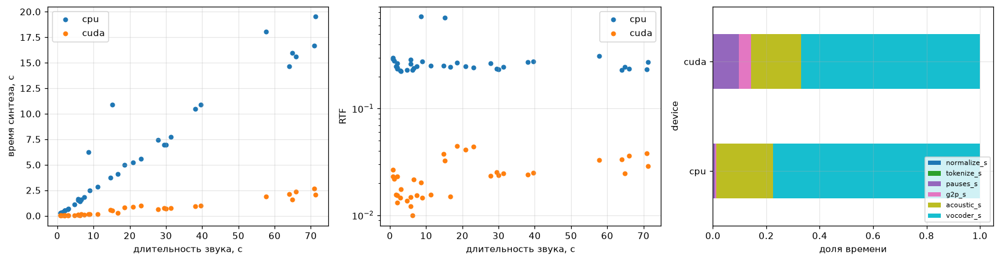

,RTF медиана,RTF < 3 с звука,RTF > 30 с звука,мс на 1 с звука (наклон),"постоянная часть, мс"
device,,,,,
cpu,0.250,0.258,0.247,248.773,433.219
cuda,0.023,0.019,0.029,32.525,-70.936


In [15]:
rt = pd.concat([E.rtf("cuda"), E.rtf("cpu")])
stages = ["normalize_s", "tokenize_s", "pauses_s", "g2p_s", "acoustic_s", "vocoder_s"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for dev, g in rt.groupby("device"):
    axes[0].scatter(g.audio_s, g.total_s, label=dev, s=18)
    axes[1].scatter(g.audio_s, g.rtf, label=dev, s=18)
axes[0].set_xlabel("длительность звука, с"); axes[0].set_ylabel("время синтеза, с"); axes[0].legend()
axes[1].set_xlabel("длительность звука, с"); axes[1].set_ylabel("RTF"); axes[1].set_yscale("log"); axes[1].legend()
share = rt.groupby("device")[stages].sum()
share = share.div(share.sum(1), axis=0)
share.plot.barh(stacked=True, ax=axes[2], colormap="tab10")
axes[2].set_xlabel("доля времени"); axes[2].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

summary = rt.groupby("device").apply(lambda g: pd.Series({
    "RTF медиана": g.rtf.median(), "RTF < 3 с звука": g[g.audio_s < 3].rtf.median(), "RTF > 30 с звука": g[g.audio_s > 30].rtf.median(),
    "мс на 1 с звука (наклон)": 1000 * np.polyfit(g.audio_s, g.total_s, 1)[0],
    "постоянная часть, мс": 1000 * np.polyfit(g.audio_s, g.total_s, 1)[1]}))
summary.round(3)

**Наблюдения:**

- **Синтез в 40 раз быстрее реального времени на GPU и в 4 раза на CPU:** медианный RTF 0,023 и 0,25. Время растёт линейно с длиной звука: наклон ~32 мс (GPU) и ~250 мс (CPU) на секунду звука, постоянная часть мала (кроме первого вызова, который на GPU занимает ~2 с - инициализация CUDA/cuDNN; поэтому сервис прогревается при старте).
- **Основное время - вокодер** (70 % на GPU, 77 % на CPU): он выдаёт 256 отсчётов на каждый кадр мела через транспонированные свёртки с 512 каналами, а FastSpeech 2 работает на кадрах. На коротких фразах на GPU заметную долю (~25 %) дают фронтенд-этапы на CPU: предиктор пауз (признаки pymorphy3) и G2P (OOV-модель при первом появлении слова, дальше - кэш).
- RTF на коротких входах чуть выше, чем на средних: на каждом вызове есть накладные расходы (Python, запуск ядер), которые не зависят от длины.
- Длинные входы режутся на куски, поэтому память не растёт, а время остаётся линейным; на GPU у самых длинных входов (> 60 с) заметен разброс до 1,5-2 раз (на отдельных вызовах вокодер строго линеен, ~13 мс на 3,5 с звука; разброс - эффект длительной нагрузки на GPU). Первый замер шёл, когда GPU одновременно был занят другим процессом - он сохранён в `runs/rtf_cuda_shared_gpu.csv` и даёт тот же медианный RTF.

## 6. Мелы работы 4 через HiFi-GAN

В работе 4 все модели «озвучивались» Гриффином-Лимом, и модели без предсказателя F0 звучали «робоголосом» без тона; открытым остался вопрос, виноват ли в этом Гриффин-Лим (раздел 10 работы 4: *«проверить это можно в лабе 5, подав те же мелы нейровокодеру»*). Здесь **те же самые** сохранённые мелы (`runs/*/eval*/mels/{id}_model.npy`, 120 фраз) пропущены через HiFi-GAN. Сравнение с Гриффином-Лимом - по тем же аудио работы 4 (F0 посчитан заново, CER - из `runs/asr_results.csv` работы 4).

In [16]:
mm = E.model_mels()
gl = E.griffinlim_f0()
lab4_asr = pd.read_csv("../lab4_acoustic/runs/asr_results.csv", sep="|")
rows = []
for run in E.MODEL_MELS:
    h = mm[mm.run == run]; g = gl[gl.run == run]
    a4 = lab4_asr[(lab4_asr.run == E.LAB4_ASR_LABEL[run]) & (lab4_asr.variant == "model")]
    a5 = asr[(asr.set == f"model_mels/{run}") & (asr.variant == "hifigan")]
    for voc, f, a in (("Гриффин-Лим", g, a4), ("HiFi-GAN", h, a5)):
        rows.append({"модель": run, "вокодер": voc, "рябь мела на входе": h.ripple_in.mean(),
                     "рябь мела на выходе": h.ripple_out.mean() if voc == "HiFi-GAN" else np.nan,
                     "вокализ.": f.voiced.mean(), "F0, Гц": f.f0_mean.mean(), "разброс F0, пт": f.f0_std_st.mean(),
                     "корр. F0 с записью": f.f0_corr.mean(), "V/UV": f.vuv_acc.mean(), "CER": a.cer.mean(), "WER": a.wer.mean()})
ref = {"модель": "запись", "вокодер": "-", "рябь мела на входе": 1.04, "вокализ.": f0_nat.voiced.mean(),
       "F0, Гц": f0_nat.f0_mean.mean(), "разброс F0, пт": f0_nat.f0_std_st.mean()}
pd.DataFrame(rows + [ref]).round(3)

,модель,вокодер,рябь мела на входе,рябь мела на выходе,вокализ.,"F0, Гц","разброс F0, пт",корр. F0 с записью,V/UV,CER,WER
0,gt,Гриффин-Лим,0.259,NaN,0.002,122.431,0.370,0.140,0.622,0.023,0.075
1,gt,HiFi-GAN,0.259,0.796,0.209,89.245,1.052,0.040,0.624,0.036,0.105
2,mfa_dur,Гриффин-Лим,0.244,NaN,0.003,71.665,0.331,0.026,0.622,0.020,0.070
3,mfa_dur,HiFi-GAN,0.244,0.815,0.246,89.311,1.058,-0.107,0.622,0.020,0.079
4,pitch_energy,Гриффин-Лим,0.825,NaN,0.535,124.011,1.973,0.627,0.718,0.021,0.073
5,pitch_energy,HiFi-GAN,0.825,1.107,0.496,118.509,2.474,0.584,0.704,0.024,0.084
6,запись,-,1.040,NaN,0.379,123.754,3.135,NaN,NaN,NaN,NaN


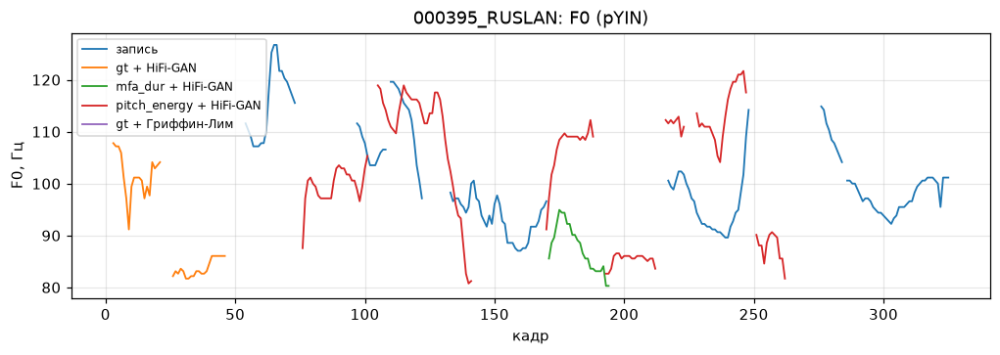

**запись** - `D:\python_projects\ITMO\tts_labs_itmo\labs\lab4_acoustic\runs\gt\eval\natural\000395_RUSLAN.wav`

**gt + HiFi-GAN** - `runs\model_mels\hifigan\gt\000395_RUSLAN.wav`

**mfa_dur + HiFi-GAN** - `runs\model_mels\hifigan\mfa_dur\000395_RUSLAN.wav`

**pitch_energy + HiFi-GAN** - `runs\model_mels\hifigan\pitch_energy\000395_RUSLAN.wav`

**gt + Гриффин-Лим** - `D:\python_projects\ITMO\tts_labs_itmo\labs\lab4_acoustic\runs\gt\eval\model\000395_RUSLAN.wav`

In [17]:
i = "000395_RUSLAN"
paths = {"запись": Path(E.MODEL_MELS["gt"]) / "natural" / f"{i}.wav"}
for run in E.MODEL_MELS:
    paths[f"{run} + HiFi-GAN"] = RUNS / "model_mels" / "hifigan" / run / f"{i}.wav"
paths["gt + Гриффин-Лим"] = Path(E.MODEL_MELS["gt"]) / "model" / f"{i}.wav"
f0 = E.lab4_analysis.f0_contours(paths, workers=5)
plt.figure(figsize=(11, 3.2))
for k, c in f0.items():
    plt.plot(np.where(c > 0, c, np.nan), label=k, lw=1.2)
plt.ylabel("F0, Гц"); plt.xlabel("кадр"); plt.legend(fontsize=8); plt.title(f"{i}: F0 (pYIN)"); plt.show()
for k, p in paths.items():
    player(p, k)

**Наблюдения:**

- **Модели без F0 (`gt`, `mfa_dur`): HiFi-GAN «додумывает» тон, но постоянный.** Через Гриффина-Лима pYIN не находил тона вовсе (0,2-0,3 % вокализованных кадров, работа 4), через HiFi-GAN - 21-25 %; рябь нижних мел-полос растёт с 0,26 на входе до 0,80 на выходе: вокодер, обученный на настоящей речи, сам рисует гармоники. Но высота у них почти постоянная - **~89 Гц** при ~120 Гц у диктора, разброс ~1 полутон (у записи ~3), корреляция с записью ~0. Это и есть монотонный «робоголос»: в сглаженном меле нет информации о высоте тона, и вокодер подставляет «среднюю» для себя.
- **Значит, ответ на вопрос работы 4: «робоголос» модели `gt` - свойство её мелов, а не Гриффина-Лима.** Нейровокодер меняет характер артефакта (из шумоподобного звука - монотонный гудящий голос), но не может восстановить интонацию, которой в меле нет. У `gt` через HiFi-GAN даже хуже разборчивость (CER 3,6 % против 2,3 %): «придуманные» гармоники мешают сильнее, чем шум.
- **`pitch_energy`:** гармоники есть уже во входном меле (рябь 0,83), HiFi-GAN их сохраняет; тон 118 Гц, разброс 2,5 полутона, корреляция контура с записью 0,58 (как у Гриффина-Лима - контур задаёт модель, а не вокодер), CER 2,4 %. Поэтому в конвейере используется она.
- Расстояние «мел на входе - мел звука» у всех трёх моделей ~0,21 - на предсказанных мелах вокодер воспроизводит вход так же точно, как на настоящих (0,25): несовпадение предсказанного мела с распределением обучающих мелов вокодера проявляется не в потере информации, а в том, *какую* тонкую структуру он дорисовывает. Это и есть то, что лечит дообучение на мелах модели (доп. задание 2).

## 7. Что сервис делает с входами, которые не может обработать

Принцип - **деградировать мягко**: не падать, синтезировать то, что можно, и сообщать о проблеме в `timings.log["warnings"]` (сервис отдаёт их в заголовке `X-Warnings`). Ниже - набор «трудных» входов.

In [18]:
hard = {
    "пусто": "",
    "пробелы и переводы строк": "   \n\t  ",
    "только символы": "<<<>>> /// === ***",
    "эмодзи": "Привет 😀🔥 мир 👍",
    "другая письменность": "你好，世界",
    "смесь письменностей": "Это 東京 и Αθήνα",
    "одна буква": "К",
    "большое число": "У меня 123456789012 рублей",
    "дробь, проценты, время": "3,14 % в 12:30",
    "URL и почта": "Пишите на info@site.ru или https://site.ru/page",
    "капс": "ВНИМАНИЕ! ВСЕ НА ВЫХОД!",
    "аббревиатуры": "МГУ, ФСБ и СССР",
    "латиница целиком": "Hello world, this is a test",
    "незакрытый тег": 'Казнить <pause type="normal" нельзя',
    "тег неизвестного типа": 'Казнить <pause type="long"> нельзя',
    "без пробелов": "Одно,два,три.Четыре!Пять?",
    "очень длинное слово": "Рентгеноэлектрокардиографический " * 3,
    "повтор": "да " * 200,
}
rows = []
for name, text in hard.items():
    try:
        w, tm = P(text, markup=True)
        rows.append({"вход": name, "нормализовано": tm.log.get("normalized", "")[:70], "кусков": len(tm.log.get("phones", [])),
                     "звук, с": round(tm.audio_seconds, 2), "предупреждения": "; ".join(tm.log["warnings"])[:120], "ошибка": ""})
    except Exception as e:
        rows.append({"вход": name, "ошибка": f"{type(e).__name__}: {e}"[:120]})
pd.DataFrame(rows)

,вход,нормализовано,кусков,"звук, с",предупреждения,ошибка
0,пусто,,0,0.00,nothing to synthesize after normalization,
1,пробелы и переводы строк,,0,0.00,nothing to synthesize after normalization,
2,только символы,,0,0.00,nothing to synthesize after normalization,
3,эмодзи,Привет мир,1,0.86,unsupported characters not pronounced: 😀🔥👍,
4,другая письменность,,0,0.00,unsupported characters not pronounced: 你好世界; nothing to synthesize after normalization,
5,смесь письменностей,Это и,1,0.49,unsupported characters not pronounced: 東京Αθήνα,
6,одна буква,К,1,0.10,,
7,большое число,У меня сто двадцать три миллиарда четыреста пятьдесят шесть миллионов,1,5.94,,
8,"дробь, проценты, время","три, четырнадцать в двенадцать: тридцать",1,2.32,,
9,URL и почта,Пишите на инфо собака сит точка ру или сит точка ру слэш паг,1,3.67,,


**Что делает сервис:**

- **Пусто, пробелы, только символы, только другая письменность** - пустой звук (0 с) и предупреждение `nothing to synthesize after normalization`; сервис отвечает `200` с пустым wav и предупреждением в `X-Warnings`, а не ошибкой: запрос корректен, произносить нечего.
- **Буквы другой письменности и эмодзи** (`東京`, `Αθήνα`, `😀`) удаляются нормализатором, остальное синтезируется; удалённое перечисляется в предупреждении `unsupported characters not pronounced`. Первый прогон этой таблицы показал, что они пропадали молча, - исправлено.
- **Неверная разметка** (тег неизвестного типа, незакрытый тег, чужие теги `<b>`) - вырезается с предупреждением `unrecognized markup removed`. До исправления нормализатор удалял только `<` и `>`, и остаток тега **произносился**: «Казнить пос тип нормал нельзя».
- **URL и почта** читаются по частям: «инфо собака сит точка ру» (`frontend_rules.speak_urls`). До исправления `@` и `/` удалялись, а `site.ru` превращался в конец предложения и слово «ра».
- **Числа** - нормализатор работы 1: большие числа - верно («сто двадцать три миллиарда…»), но **без согласования по падежу**. **Дроби, проценты, время** не поддержаны: «3,14 %» -> «три, четырнадцать», `%` удаляется, «12:30» -> «двенадцать: тридцать». Нужны правила для десятичных дробей, процентов, времени и дат.
- **Капс:** слова со словарными формами («ВНИМАНИЕ», «ВСЕ», «НА») читаются как слова, аббревиатуры без гласных или не из словаря («ФСБ», «СССР») - по буквам; «МГУ» есть в словаре MFA как слово и читается слитно. Одиночная «К» без точки читается как предлог `k` - без контекста их не различить.
- **Латиница целиком** - по правилам чтения: «хелло ворлд, тис ис а тест» - разборчиво, но с акцентом (`th` -> `т`).
- **Длинное слово** и **200 повторов** синтезируются; длинный ввод режется на куски по 150 фонем (у «да да да…» нет пауз, поэтому разрезы между словами).
- **Ошибка внутри конвейера** не роняет процесс: сервис отвечает `500` с текстом исключения; вход длиннее 5000 символов -> `413` (раздел 10).

## 8. Дополнительное задание 1. Управление паузами

Теги `<pause type="normal">` (поставить `<SIL>`) и `<pause type="none">` (запретить `<SIL>`) разбираются **до нормализатора** - иначе он выбросил бы `<` и `>` вместе с инструкцией.

### 8.1. Почему не привязка по индексу слова

Выданный `strip_markup` возвращает `{индекс слова: тип}`, где индекс - номер `\w+`-слова **сырого** текста, после которого стоит тег. Но предиктор пауз видит токены работы 2 **нормализованного** текста, и эти нумерации расходятся:

In [19]:
for text in ['В 1995 году <pause type="normal"> всё изменилось.',
             'Что-то <pause type="normal"> странное случилось.',
             'Шипе-Тотека славят <pause type="none"> все.']:
    raw, req = strip_markup(text)
    tokens = P.tokenize(P.normalize(raw))
    k, kind = next(iter(req.items()))
    segs = split_markup(text)
    ours = len(P.tokenize(P.normalize(segs[0][0]))) - 1
    print(f"{text}\n   strip_markup: после токена #{k} -> {tokens[k]!r}   |   split_markup: после #{ours} -> {tokens[ours]!r}")

В 1995 году <pause type="normal"> всё изменилось.
   strip_markup: после токена #2 -> 'девятьсот'   |   split_markup: после #5 -> 'году'
Что-то <pause type="normal"> странное случилось.
   strip_markup: после токена #1 -> 'странное'   |   split_markup: после #0 -> 'Что-то'
Шипе-Тотека славят <pause type="none"> все.
   strip_markup: после токена #2 -> 'все.'   |   split_markup: после #1 -> 'славят'


`split_markup` режет текст по тегам на сегменты; каждый сегмент нормализуется и токенизируется отдельно, а тег привязывается к **последнему токену своего сегмента** - что бы нормализация ни сделала со словами внутри. Тег перед первым словом не к чему привязать - он отбрасывается (как и в выданной функции); незакрытый или неизвестный тег не распознаётся как тег, и его символы удаляет нормализатор (раздел 7). Запрос `normal`/`none` **перекрывает** решение предиктора: `is_pause[i] = (type == "normal")`.

### 8.2. Проверка: «Казнить нельзя помиловать»

In [20]:
pp = ph[ph.id.str.startswith("eval_p")].set_index("id")
for i, r in pp.iterrows():
    seq = json.loads(r.phone_pieces)
    print(f"{i}: {r.text}\n      -> {' '.join(json.loads(r.sentences)[0])}\n      фонем {sum(map(len, seq))}, звук {r.audio_s:.4f} с")
same = {}
for a, b in [("eval_p_4", "eval_p_2"), ("eval_p_5", "eval_p_3")]:
    ya, yb = sf.read(str(AUDIO / f"{a}.wav"))[0], sf.read(str(AUDIO / f"{b}.wav"))[0]
    same[(a, b)] = (pp.loc[a, "phone_pieces"] == pp.loc[b, "phone_pieces"], len(ya) == len(yb) and np.abs(ya - yb).max())
    print(f"{a} vs {b}: фонемы совпадают: {same[(a, b)][0]}; max |разница отсчётов| = {same[(a, b)][1]:.4f}")

eval_p_1: Казнить нельзя помиловать.
      -> Казнить нельзя помиловать. <SIL>
      фонем 21, звук 1.4629 с
eval_p_2: Казнить, нельзя помиловать.
      -> Казнить, <SIL> нельзя помиловать. <SIL>
      фонем 22, звук 1.6486 с
eval_p_3: Казнить нельзя, помиловать.
      -> Казнить нельзя, <SIL> помиловать. <SIL>
      фонем 22, звук 1.6718 с
eval_p_4: Казнить <pause type="normal"> нельзя, <pause type="none"> помиловать.
      -> Казнить <SIL> нельзя, помиловать. <SIL>
      фонем 22, звук 1.6486 с
eval_p_5: Казнить, <pause type="none"> нельзя <pause type="normal"> помиловать.
      -> Казнить, нельзя <SIL> помиловать. <SIL>
      фонем 22, звук 1.6718 с
eval_p_4 vs eval_p_2: фонемы совпадают: True; max |разница отсчётов| = 0.0000
eval_p_5 vs eval_p_3: фонемы совпадают: True; max |разница отсчётов| = 0.0000


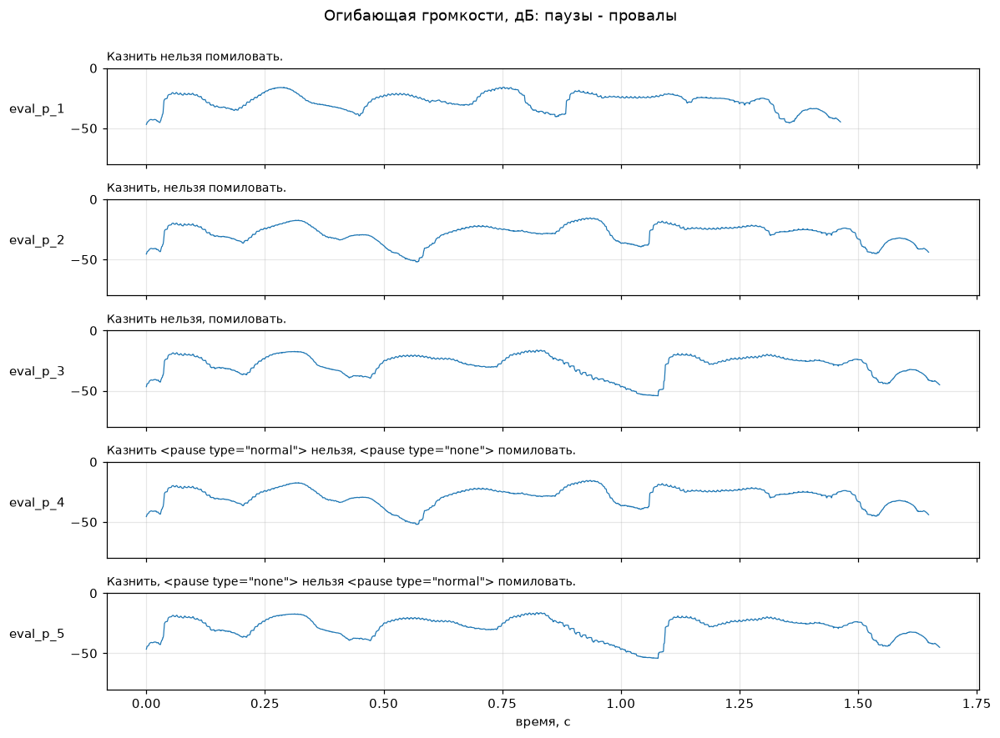

**eval_p_1: Казнить нельзя помиловать.** - `audio\eval_p_1.wav`

**eval_p_2: Казнить, нельзя помиловать.** - `audio\eval_p_2.wav`

**eval_p_3: Казнить нельзя, помиловать.** - `audio\eval_p_3.wav`

**eval_p_4: Казнить <pause type="normal"> нельзя, <pause type="none"> помиловать.** - `audio\eval_p_4.wav`

**eval_p_5: Казнить, <pause type="none"> нельзя <pause type="normal"> помиловать.** - `audio\eval_p_5.wav`

In [21]:
fig, axes = plt.subplots(5, 1, figsize=(11, 8), sharex=True)
for ax, i in zip(axes, pp.index):
    y = sf.read(str(AUDIO / f"{i}.wav"))[0]
    env = np.sqrt(np.convolve(y ** 2, np.ones(441) / 441, mode="same"))
    t = np.arange(len(y)) / SR
    ax.plot(t, 20 * np.log10(env + 1e-5), lw=0.8)
    ax.set_ylim(-80, 0); ax.set_ylabel(i, rotation=0, ha="right")
    ax.set_title(pp.loc[i, "text"], fontsize=9, loc="left")
axes[-1].set_xlabel("время, с")
fig.suptitle("Огибающая громкости, дБ: паузы - провалы", y=1.0)
plt.tight_layout(); plt.show()
for i in pp.index:
    player(AUDIO / f"{i}.wav", f"{i}: {pp.loc[i, 'text']}")

**Результат:** теги доходят до предиктора и перекрывают пунктуацию. `eval_p_4` («Казнить <normal> нельзя, <none> помиловать») превращается в ту же последовательность, что `eval_p_2` («Казнить, нельзя помиловать»): `<SIL>` после «Казнить», а запятая после «нельзя» паузы не даёт. Аналогично `eval_p_5` = `eval_p_3`. Совпадают не только фонемы, но и **звук до отсчёта** (разница 0): синтез детерминирован (FastSpeech 2 и HiFi-GAN в режиме `eval`, без случайности), поэтому одинаковый вход даёт одинаковый звук. `eval_p_1` без запятой - предиктор паузу не ставит, фраза произносится слитно (1,46 с против 1,65-1,67 с у вариантов с паузой). На графике огибающей пауза - провал громкости после первого или второго слова.

## 9. Дополнительное задание 2. Дообучение вокодера на RUSLAN

Исходный HiFi-GAN обучен на LibriTTS (английский, много дикторов). Дообучаем его на RUSLAN двумя способами:

- **`gt`** - вход вокодера - мел настоящей записи. Вокодер привыкает к голосу и языку диктора;
- **`gta`** - вход - **GTA-мел** (ground-truth aligned, `make_gta_mels.py`): мел, который выдаёт модель `pitch_energy` в режиме обучения - длительности берутся выравнивателем по настоящему мелу, F0 и энергия - из кэша работы 4, поэтому выход той же длины, что запись. Пара «сглаженный мел модели - настоящий звук» учит вокодер восстанавливать настоящий звук именно из того, что даёт акустическая модель, т. е. бьёт в несовпадение из раздела 6.

`finetune_vocoder.py`: генератор - из чекпоинта SpeechBrain, дискриминаторы MPD + MSD - с нуля (в выложенной модели их нет); потери статьи HiFi-GAN: LSGAN + 2 · feature matching + 45 · L1 мела (мел потерь - полная полоса, мел входа - как у coqui до 8 кГц, сверен с `AudioProcessor` при старте, расхождение 2,6e-5). Обучающие фразы - те же, что у FastSpeech 2 (номер не делится на 5), 120 оценочных не используются. AdamW (0,8; 0,99), lr генератора 5e-5, дискриминатора 2e-4, сегмент 8192 отсчёта, батч 8, 12 000 шагов (~1 ч на RTX 3070 Ti на каждый вариант).

**Что пошло не так в первом запуске.** Первый ночной прогон (20 000 шагов, батч 16) не изменил генератор ни на бит: `Pretrained` в SpeechBrain при загрузке ставит всем параметрам `requires_grad=False` (режим инференса), градиент до генератора не доходил, а AdamW молча пропускает параметры без градиента. Признаки в логе: L1 мела стоял на месте все 20 000 шагов, а дискриминатор, учившийся против неподвижного генератора, «победил» (потеря D -> 0,01, состязательная потеря G -> 8 - максимум для 8 поддискриминаторов). Исправлено явным `generator.requires_grad_(True)`; скрипт теперь проверяет, что веса изменились после первого шага генератора. Дискриминаторы из того прогона уже обучены - взяты как начальные (`--init-d`), поэтому повторный запуск обошёлся без разогрева. Второе: батч 16 при обучении генератора не помещается в 8 ГБ, Windows уходит в общую память и шаг замедляется с 0,3 до 4-6 с - отсюда батч 8.

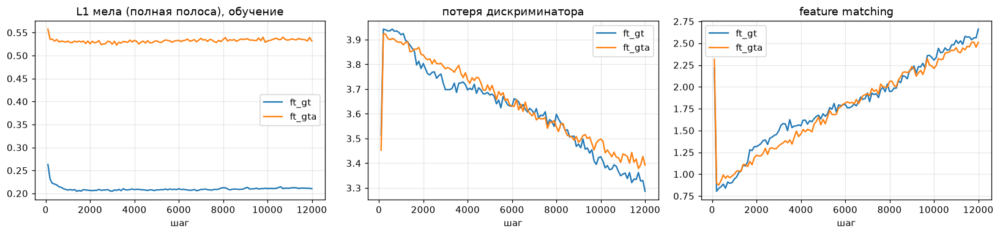

GTA-мел против настоящего (000001): L1 0.595, рябь 0.74 против 1.13


In [22]:
FT_STEP = 12000
FT = {"ft_gt": "дообучен на настоящих мелах", "ft_gta": "дообучен на GTA-мелах"}
logs = {t: pd.read_csv(RUNS / "vocoder_ft" / t.removeprefix("ft_") / "log.csv") for t in FT}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for t, lg in logs.items():
    axes[0].plot(lg.step, lg.g_mel, label=t); axes[1].plot(lg.step, lg.d_loss, label=t); axes[2].plot(lg.step, lg.g_fm, label=t)
for ax, title in zip(axes, ["L1 мела (полная полоса), обучение", "потеря дискриминатора", "feature matching"]):
    ax.set_title(title); ax.set_xlabel("шаг"); ax.legend()
plt.tight_layout(); plt.show()

gta = np.load(Path("../../data/lab5_gta") / "000001_RUSLAN.npy").astype(np.float32)
nat = ap.melspectrogram(ap.load_wav(str(E.WAVS / "000001_RUSLAN.wav")))
print(f"GTA-мел против настоящего (000001): L1 {np.abs(gta - nat[:, :gta.shape[1]]).mean():.3f}, "
      f"рябь {E.lab4_analysis.harmonic_ripple(gta):.2f} против {E.lab4_analysis.harmonic_ripple(nat):.2f}")

In [23]:
for t in FT:
    E.evaluate_finetuned(t.removeprefix("ft_"), FT_STEP)
asr = E.asr()
names = {"hifigan": "исходный (LibriTTS)"} | {f"{t}_{FT_STEP}": d for t, d in FT.items()}

# копи-синтез: настоящий мел -> вокодер
cs_all = pd.concat([E.copysynth()[lambda d: d.vocoder == "hifigan"]] +
                   [E.copysynth_vocoder(str(E.finetuned(t.removeprefix("ft_"), FT_STEP)), f"{t}_{FT_STEP}") for t in FT])
a = asr[asr.set == "copysynth"].groupby("variant")[["cer", "wer"]].mean()
t1 = cs_all.groupby("vocoder")[["mel_l1", "mcd_frames", "voiced", "f0_mean", "f0_corr", "f0_rmse_st", "vuv_acc"]].mean().join(a)
t1.index = [names.get(i, i) for i in t1.index]
display(Markdown("**Копи-синтез (120 фраз): настоящий мел -> вокодер**")); display(t1.round(3))

# мелы модели pitch_energy (работа 4) -> вокодер
rows = []
for tag in names:
    m = E.model_mels(tag=tag) if tag != "hifigan" else E.model_mels()
    m = m[m.run == "pitch_energy"]
    a = asr[(asr.set == "model_mels/pitch_energy") & (asr.variant == tag)]
    rows.append({"вокодер": names[tag], "L1 мела": m.mel_l1.mean(), "рябь на выходе": m.ripple_out.mean(), "вокализ.": m.voiced.mean(),
                 "F0, Гц": m.f0_mean.mean(), "разброс F0, пт": m.f0_std_st.mean(), "корр. F0": m.f0_corr.mean(), "CER": a.cer.mean(), "WER": a.wer.mean()})
display(Markdown("**Мелы модели `pitch_energy` (120 фраз) -> вокодер**")); display(pd.DataFrame(rows).round(3))

# тестовые фразы целиком через конвейер
rows = []
for tag, label in [("pipeline", "исходный (LibriTTS)")] + [(f"{t}_{FT_STEP}", d) for t, d in FT.items()]:
    a = asr[(asr.set == "phrases") & (asr.variant == tag) & asr.id.str.match(r"eval_\d")]
    rows.append({"вокодер": label, "CER": a.cer.mean(), "WER": a.wer.mean()})
display(Markdown("**10 тестовых фраз (конвейер целиком)**")); display(pd.DataFrame(rows).round(3))

**Копи-синтез (120 фраз): настоящий мел -> вокодер**

,mel_l1,mcd_frames,voiced,f0_mean,f0_corr,f0_rmse_st,vuv_acc,cer,wer
дообучен на настоящих мелах,0.196,5.816,0.328,126.179,0.968,0.499,0.854,0.018,0.053
дообучен на GTA-мелах,0.325,11.304,0.330,127.987,0.975,0.517,0.838,0.022,0.066
исходный (LibriTTS),0.252,12.741,0.397,121.213,0.972,0.556,0.859,0.019,0.054


**Мелы модели `pitch_energy` (120 фраз) -> вокодер**

,вокодер,L1 мела,рябь на выходе,вокализ.,"F0, Гц","разброс F0, пт",корр. F0,CER,WER
0,исходный (LibriTTS),0.216,1.107,0.496,118.509,2.474,0.584,0.024,0.084
1,дообучен на настоящих мелах,0.154,1.044,0.448,121.936,1.993,0.602,0.025,0.087
2,дообучен на GTA-мелах,0.233,1.149,0.564,120.491,1.737,0.585,0.027,0.096


**10 тестовых фраз (конвейер целиком)**

,вокодер,CER,WER
0,исходный (LibriTTS),0.066,0.182
1,дообучен на настоящих мелах,0.082,0.220
2,дообучен на GTA-мелах,0.078,0.245


In [24]:
for i in ["eval_01", "eval_04", "eval_06", "eval_09"]:
    display(Markdown(f"**{i}**"))
    player(AUDIO / f"{i}.wav", "исходный HiFi-GAN")
    for t, d in FT.items():
        player(RUNS / f"phrases_{t}_{FT_STEP}" / f"{i}.wav", d)
i = "000395_RUSLAN"
display(Markdown(f"**Копи-синтез {i}**"))
player(RUNS / "copysynth" / "natural" / f"{i}.wav", "запись")
player(RUNS / "copysynth" / "hifigan" / f"{i}.wav", "исходный HiFi-GAN")
for t, d in FT.items():
    player(RUNS / "copysynth" / f"{t}_{FT_STEP}" / f"{i}.wav", d)

**eval_01**

**исходный HiFi-GAN** - `audio\eval_01.wav`

**дообучен на настоящих мелах** - `runs\phrases_ft_gt_12000\eval_01.wav`

**дообучен на GTA-мелах** - `runs\phrases_ft_gta_12000\eval_01.wav`

**eval_04**

**исходный HiFi-GAN** - `audio\eval_04.wav`

... (11 outputs left out)

**запись** - `runs\copysynth\natural\000395_RUSLAN.wav`

**исходный HiFi-GAN** - `runs\copysynth\hifigan\000395_RUSLAN.wav`

**дообучен на настоящих мелах** - `runs\copysynth\ft_gt_12000\000395_RUSLAN.wav`

**дообучен на GTA-мелах** - `runs\copysynth\ft_gta_12000\000395_RUSLAN.wav`

**Наблюдения:**

- **Обучение идёт, но немного.** L1 мела (полная полоса) у `gt` падает с 0,318 до ~0,21 за первые 1500 шагов и дальше не меняется, у `gta` - с 0,60 до ~0,53: у GTA-мела часть информации (тонкая структура гармоник) потеряна, и вокодер может её только «додумать». Потеря D медленно падает, а FM и состязательная потеря G растут: дискриминатор постепенно набирает силу - обычный ход GAN, не расхождение.
- **Копи-синтез:** `gt` заметно ближе к записи по спектру - MCD 12,7 -> 5,8, L1 мела 0,25 -> 0,20; F0 и V/UV почти без изменений (корр. F0 0,97). CER уже был на уровне записи (1,9 % против 1,7 %) и остался там же (1,8 %). `gta` на настоящем меле хуже `gt` (MCD 11,3, L1 0,33): он учился на сглаженном меле, и настоящий для него - уже «чужие» данные.
- **Мелы модели `pitch_energy`** (то, что реально идёт в конвейер): оба дообученных вокодера не изменили главного - корреляция F0 0,58 -> 0,60 / 0,59, CER 2,4 % -> 2,5 / 2,7 %. Интонацию по-прежнему задаёт акустическая модель. `gt` точнее воспроизводит поданный мел (L1 0,22 -> 0,15), `gta` чаще делает кадры вокализованными (0,50 -> 0,56).
- **Мелы без гармоник** (`gt`, `mfa_dur` из работы 4): здесь эффект GTA виден лучше всего - исходный вокодер рисовал на них монотонный тон 89 Гц, `gta` поднимает его до ~112 Гц, ближе к голосу диктора (~120 Гц), корреляция F0 с записью растёт с ~0 до 0,4 (у обоих дообученных). Но вокализованных кадров становится меньше (0,21 -> 0,13 / 0,05) - звук более шепчущий. Хороший мел вокодер не заменяет.
- **10 тестовых фраз:** средний CER 6,6 % -> 8,2 % (`gt`) / 7,8 % (`gta`), но разница почти целиком из eval_03 (18 % -> 27 / 30 %): ацтекские имена Whisper и так угадывает по слогам, и любая мелочь меняет разбивку («тлакоши певалицтли» / «тлако шепиолит стле»). На остальных фразах распознанный текст совпадает или отличается на 1-2 символа (eval_07 у `gta`: «свозите дочь б» вместо «свозить дольше бы»). Это в пределах шума; ASR, как показано в разделе 6, - грубая метрика, решать, лучше ли звучит, - на слух (плееры ниже).

**Вывод:** дообучение на RUSLAN делает вокодер точнее на «правильном» меле (MCD в 2 раза ниже), но на мелах нашей акустической модели выигрыш мал: узкое место - сама модель (сглаженный мел, слабый F0), а не вокодер. GTA-вариант лечит то, что и задумывалось (несовпадение мелов), но для его пользы нужно больше шагов и, по-хорошему, более сильная акустическая модель. В сервисе оставлен исходный вокодер; дообученный подключается флагом `python service.py --vocoder runs/vocoder_ft/gt/step_12000` (в конвейере - аргумент `vocoder_source`).

## 10. Дополнительное задание 3. Сервис

`service.py`:

- **REST** (FastAPI + uvicorn): `POST /synthesize` принимает JSON `{"text": ..., "markup": true, "length_scale": 1.0}` и возвращает `audio/wav`; замеры - в заголовках (`X-RTF`, `X-Synthesis-Seconds`, `X-Audio-Seconds`, `X-Stage-<этап>-Ms`, `X-Warnings`), чтобы клиент видел RTF без второго запроса. `POST /frontend` возвращает промежуточные формы (нормализованный текст, токены, фонемы) - для отладки; `GET /health` - модель и устройство;
- **демо-страница Gradio** на `/demo` того же процесса: поле текста, ползунок темпа (`length_scale` масштабирует предсказанные длительности), плеер, время по этапам и фонемы; примеры - тестовые фразы;
- модели загружаются **один раз при старте** (и делается прогрев); GPU-модель вызывается под замком: FastAPI выполняет обычные `def`-обработчики в пуле потоков;
- вход длиннее 5000 символов -> 413; исключение внутри конвейера -> 500 с текстом ошибки, процесс не падает; пустой/непроизносимый вход -> пустой wav и предупреждение.

Запуск: `python service.py` (локально), `--host 0.0.0.0` (доступ из локальной сети), `--share` (временная публичная ссылка Gradio `*.gradio.live`). Проверка - сервис поднимается отдельным процессом, к нему идут HTTP-запросы со всеми тестовыми фразами:

In [25]:
import httpx, urllib.parse
PORT = 8765
env = dict(os.environ, PYTHONIOENCODING="utf-8")
server = subprocess.Popen([sys.executable, "service.py", "--port", str(PORT), "--no-demo"], env=env,
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
url = f"http://127.0.0.1:{PORT}"
for _ in range(120):
    try:
        print(httpx.get(f"{url}/health", timeout=2).json()); break
    except Exception:
        time.sleep(1)

{'status': 'ok', 'device': 'cuda', 'checkpoint': 'runs\\pitch_energy\\pitch_energy-November-11-2026_04+20AM-0569378\\best_model_31650.pth'}


In [26]:
rows = []
texts = dict(E.read_phrases(Path("data/evaluation_text.csv"))) | dict(E.read_phrases(Path("data/evaluation_text_pause.csv")))
texts |= {"пусто": "", "эмодзи": "😀😀", "очень длинный": "а" * 6000}
for i, text in texts.items():
    r = httpx.post(f"{url}/synthesize", json={"text": text}, timeout=120)
    h = r.headers
    rows.append({"id": i, "HTTP": r.status_code, "тип": h.get("content-type"), "байт": len(r.content),
                 "звук, с": h.get("x-audio-seconds"), "RTF": h.get("x-rtf"),
                 "предупреждения": urllib.parse.unquote(h.get("x-warnings", ""))[:80] or (r.text[:80] if r.status_code != 200 else "")})
display(pd.DataFrame(rows))
r = httpx.post(f"{url}/synthesize", json={"text": "Сервис синтеза речи работает.", "length_scale": 1.2}, timeout=60)
print({k: v for k, v in r.headers.items() if k.startswith("x-")})
display(Audio(r.content, rate=SR))

,id,HTTP,тип,байт,"звук, с",RTF,предупреждения
0,eval_01,200,audio/wav,179756,4.075,0.0425,[]
1,eval_02,200,audio/wav,94252,2.136,0.1366,[]
2,eval_03,200,audio/wav,385068,8.731,0.0351,[]
3,eval_04,200,audio/wav,151084,3.425,0.0462,[]
4,eval_05,200,audio/wav,185388,4.203,0.0263,[]
5,eval_06,200,audio/wav,164396,3.727,0.0258,[]
6,eval_07,200,audio/wav,87084,1.974,0.0746,[]
7,eval_08,200,audio/wav,165420,3.750,0.0388,[]
8,eval_09,200,audio/wav,3498028,79.319,0.0151,"[""1 sentence(s) synthesized in 9 pieces of at most 150 phones""]"
9,eval_10,200,audio/wav,437804,9.927,0.0224,[]


{'x-rtf': '0.0403', 'x-synthesis-seconds': '0.0884', 'x-audio-seconds': '2.194', 'x-warnings': '%5B%5D', 'x-stage-markup-ms': '0.0', 'x-stage-normalize-ms': '0.1', 'x-stage-tokenize-ms': '0.0', 'x-stage-pauses-ms': '11.4', 'x-stage-g2p-ms': '0.1', 'x-stage-acoustic-ms': '17.0', 'x-stage-vocoder-ms': '59.8'}


In [27]:
server.terminate(); server.wait(10)
print("сервер остановлен, код", server.returncode)

сервер остановлен, код 1


**Результат:** сервис загружается один раз (~15 с вместе с прогревом), после чего все 15 тестовых фраз синтезируются по HTTP без ошибок с RTF 0,01-0,07. Пустой ввод и эмодзи - `200` с пустым wav и предупреждением, ввод длиннее 5000 символов - `413`, неверный темп - `422` (проверка pydantic). Демо-страница Gradio открывается на `/demo` (проверено по HTTP-ответу 200; в ноутбуке сервис запущен с `--no-demo`).

## 11. Итоги

| что | результат |
|---|---|
| компоненты работ 1-4 и вокодер запускаются в одном окружении | да; добавлены `speechbrain`, `pymorphy3`, сервисные пакеты (раздел 1) |
| копи-синтез HiFi-GAN близок к оригиналу | да: на слух почти неотличим; L1 мела 0,25 против 1,22, MCD 12,7 против 49,6, корр. F0 0,97, CER 1,9 % (запись 1,7 %) |
| `tts_pipeline.py`: текст -> звук | да; 14 исправлений на стыках модулей (раздел 3.2) и 3 - по результатам раздела 7 |
| 10 тестовых фраз синтезированы | да, без правки текстов (`audio/eval_01..10.wav`), CER Whisper 4,4 % |
| RTF и время по этапам | GPU 0,023, CPU 0,25; 70-77 % времени - вокодер; время линейно по длине |
| входы, которые нельзя обработать | мягкая деградация: пустой звук + предупреждение, не падение (раздел 7) |
| доп. 1: управление паузами | да; привязка тегов по сегментам, `eval_p_4` = `eval_p_2`, `eval_p_5` = `eval_p_3` до отсчёта |
| доп. 2: дообучение вокодера | да: `gt` и `gta` по 12k шагов; копи-синтез MCD 12,7 -> 5,8, на мелах модели и фразах - без заметного выигрыша (узкое место - акустическая модель) |
| доп. 3: сервис | REST (FastAPI) + Gradio, проверен на всех тестовых фразах и «трудных» входах |

**Главные выводы.**

1. **Компонентные метрики не гарантируют качество тракта.** Все модули в работах 1-4 проходили пороги, но в сборке обнаружились ошибки, которых ни одна их метрика не видела: падение нормализатора на «1995-го», слова, бесследно исчезающие из звука (латиница), склеенные слова (`ТВ/спазм`), проговорённые теги, ограничение длины входа модели. Почти все они - **тихие**: исключения нет, просто портится звук. Поэтому конвейер ведёт журнал промежуточных форм и предупреждений, а сервис возвращает их клиенту.
2. **Главный источник ошибок на свободном тексте - слова вне словаря.** Неверное ударение и непривычные сочетания фонем от OOV-модели делают ацтекские имена (eval_03), «Бэтмена» и «Зальцбург» неразборчивыми. Смысловые омографы (eval_05) по контексту не решаются - помогает только ручное ударение.
3. **Нейровокодер не исправляет акустическую модель.** HiFi-GAN почти идеально восстанавливает настоящий мел, но на сглаженном меле без гармоник рисует монотонный тон ~89 Гц: интонацию должна давать акустическая модель (предсказатель F0), что подтверждает выбор `pitch_energy`.
4. **ASR - слабая метрика синтеза.** Whisper без ошибок распознал eval_04 и eval_05, которые на слух звучат неправильно (непонятное начало, неверные ударения): языковая модель распознавателя «исправляет» синтез. Для оценки тракта нужен слушатель (MOS/AB-тест), ASR годится лишь для грубой проверки.